# Reference paper

- [Distilling the Knowledge in a Neural Network]
  (https://arxiv.org/abs/1503.02531)

In [1]:
import numpy as np
%matplotlib inline
from matplotlib import pyplot as plt
import tensorflow as tf
from tensorflow import keras
from nets.resnet_cifar10 import ResNet11, ResNet56

In [8]:
seed = 333
data_augmentation = False
epochs = 50
batch_size = 128
temperature = 3.
_lambda = 0.5
use_lrschedule_for_distill_net = False

In [3]:
def lr_schedule(epoch):
    lr = 1e-3
    if epoch >= 45:
        lr *= 1e-3
    elif epoch >= 35:
        lr *= 1e-2
    elif epoch >= 25:
        lr *= 1e-1
    return lr

lr_scheduler = keras.callbacks.LearningRateScheduler(lr_schedule)

class LRSchedule(keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, lrfn, train_steps_per_epoch):
        self.lrfn = tf.function(lrfn)
        self.train_steps_per_epoch = train_steps_per_epoch
    def __call__(self, step):
        return self.lrfn(epoch=step//tf.cast(self.train_steps_per_epoch,tf.float32))

In [4]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

x_train_mean = np.mean(x_train, axis=0)
x_train -= x_train_mean
x_test -= x_train_mean

def random_shift(image):
    return  keras.preprocessing.image.random_shift(image, 0.1, 0.1,  row_axis=0, col_axis=1, channel_axis=2)

def augment(image, label):
    image = tf.numpy_function(random_shift, [image], tf.float32)
    image = tf.image.random_flip_left_right(image)
    return image, label

train_ds = tf.data.Dataset.from_tensor_slices((x_train,y_train))
train_ds = train_ds.shuffle(10000, seed=seed)
if data_augmentation:
    train_ds = train_ds.map(augment)
train_ds = train_ds.batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)
train_steps_per_epoch = tf.data.experimental.cardinality(train_ds)

test_ds = tf.data.Dataset.from_tensor_slices((x_test,y_test))
test_ds = test_ds.batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

In [5]:
student_net = ResNet11(input_shape=(32,32,3),num_classes=10)
student_net.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              optimizer='adam',
              metrics=['accuracy'])
history_student_nkd = student_net.fit(train_ds,epochs=epochs,validation_data=(test_ds), callbacks=[lr_scheduler])

Train for 391 steps, validate for 79 steps
Epoch 1/50
391/391 [==============================] - 33s 84ms/step - loss: 1.8814 - accuracy: 0.3952 - val_loss: 2.2546 - val_accuracy: 0.3032
Epoch 2/50
391/391 [==============================] - 29s 73ms/step - loss: 1.5290 - accuracy: 0.5163 - val_loss: 1.5769 - val_accuracy: 0.5095
Epoch 3/50
391/391 [==============================] - 29s 73ms/step - loss: 1.3845 - accuracy: 0.5667 - val_loss: 1.3170 - val_accuracy: 0.5902
Epoch 4/50
391/391 [==============================] - 29s 74ms/step - loss: 1.2807 - accuracy: 0.6025 - val_loss: 1.2218 - val_accuracy: 0.6230
Epoch 5/50
391/391 [==============================] - 29s 74ms/step - loss: 1.2071 - accuracy: 0.6230 - val_loss: 1.2272 - val_accuracy: 0.6175
Epoch 6/50
391/391 [==============================] - 29s 75ms/step - loss: 1.1522 - accuracy: 0.6468 - val_loss: 1.1207 - val_accuracy: 0.6533
Epoch 7/50
391/391 [==============================] - 29s 75ms/step - loss: 1.1093 - accuracy

In [6]:
teacher_net = ResNet56(input_shape=(32,32,3),num_classes=10)
teacher_net.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              optimizer='adam',
              metrics=['accuracy'])
history_teacher = teacher_net.fit(train_ds,epochs=epochs,validation_data=(test_ds), callbacks=[lr_scheduler])

Train for 391 steps, validate for 79 steps
Epoch 1/50
391/391 [==============================] - 160s 408ms/step - loss: 2.3295 - accuracy: 0.3831 - val_loss: 2.5529 - val_accuracy: 0.2973
Epoch 2/50
391/391 [==============================] - 151s 385ms/step - loss: 1.6936 - accuracy: 0.5204 - val_loss: 1.9562 - val_accuracy: 0.4419
Epoch 3/50
391/391 [==============================] - 152s 388ms/step - loss: 1.4436 - accuracy: 0.5914 - val_loss: 1.5480 - val_accuracy: 0.5566
Epoch 4/50
391/391 [==============================] - 148s 379ms/step - loss: 1.2839 - accuracy: 0.6439 - val_loss: 1.9032 - val_accuracy: 0.4924
Epoch 5/50
391/391 [==============================] - 147s 376ms/step - loss: 1.1796 - accuracy: 0.6800 - val_loss: 1.2786 - val_accuracy: 0.6544
Epoch 6/50
391/391 [==============================] - 148s 379ms/step - loss: 1.0973 - accuracy: 0.7073 - val_loss: 1.1669 - val_accuracy: 0.6929
Epoch 7/50
391/391 [==============================] - 147s 375ms/step - loss: 1.0

In [9]:
ce_loss_object = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
kd_loss_object = keras.losses.KLDivergence()
train_accuracy = keras.metrics.SparseCategoricalAccuracy(name="train_accuracy")
train_ce_loss = keras.metrics.Mean(name="train_ce_loss")
train_kd_loss = keras.metrics.Mean(name="train_kd_loss")
train_loss = keras.metrics.Mean(name="train_loss")

test_accuracy = keras.metrics.SparseCategoricalAccuracy(name="test_accuracy")
test_ce_loss = keras.metrics.Mean(name="test_ce_loss")
test_kd_loss = keras.metrics.Mean(name="test_kd_loss")
test_loss = keras.metrics.Mean(name="test_loss")


student_kd_net = ResNet11(input_shape=(32,32,3),num_classes=10)
history_student_kd = []

if use_lrschedule_for_distill_net:
    optimizer = keras.optimizers.Adam(learning_rate=LRSchedule(lr_schedule, train_steps_per_epoch))
else:
    optimizer = keras.optimizers.Adam()

def kd_loss(y_knowledge, y_predict):
    y_knowledge_T = keras.activations.softmax(y_knowledge/temperature)
    y_predict_T = keras.activations.softmax(y_predict/temperature)
    kd_losses = tf.square(temperature)*kd_loss_object(y_knowledge_T, y_predict_T)
    return kd_losses

def ce_loss(y_true, y_predict):
    y_predict = keras.activations.softmax(y_predict)
    ce_losses = ce_loss_object(y_true,y_predict)
    return ce_losses

@tf.function
def train_step(inputs):
    images, labels = inputs
    knowledges = teacher_net(inputs, training=False)
    with tf.GradientTape() as tape:
        logits = student_kd_net(images, training=True)
        kd_losses = kd_loss(knowledges, logits)
        ce_losses = ce_loss(labels, logits)
        total_losses = _lambda*ce_losses + (1-_lambda)*kd_losses

    gradients = tape.gradient(total_losses, student_kd_net.trainable_variables)
    optimizer.apply_gradients(zip(gradients, student_kd_net.trainable_variables))
    train_accuracy(labels, logits)
    train_ce_loss(ce_losses)
    train_kd_loss(kd_losses)
    train_loss(total_losses)

@tf.function
def test_step(inputs):
    images, labels = inputs
    knowledges = teacher_net(inputs, training=False)
    logits = student_kd_net(images, training=False)
    kd_losses = kd_loss(knowledges, logits)
    ce_losses = ce_loss(labels, logits)
    total_losses = _lambda*ce_losses + (1-_lambda)*kd_losses
    test_accuracy(labels, logits)
    test_ce_loss(ce_losses)
    test_kd_loss(kd_losses)
    test_loss(total_losses)

In [10]:
for epoch in range(epochs):
    train_loss.reset_states()
    train_ce_loss.reset_states()
    train_kd_loss.reset_states()
    train_accuracy.reset_states()
    test_loss.reset_states()
    test_ce_loss.reset_states()
    test_kd_loss.reset_states()
    test_accuracy.reset_states()
    for data in train_ds:
        train_step(data)
    

    for data in test_ds:
        test_step(data)
    
    history_student_kd.append(test_accuracy.result())
    print(
      f"Epoch: {epoch+1} \nTrain Losses: {train_loss.result()} "
      f"Train CE Losses: {train_ce_loss.result()} Train KD Losses: {train_kd_loss.result()} "
      f"Train Accuracy: {train_accuracy.result()*100} \n"
      f"Test Losses: {test_loss.result()} " 
      f"Test CE Losses: {test_ce_loss.result()} Test KD Losses: {test_kd_loss.result()} "
      f"Test Accuracy: {test_accuracy.result()*100}"
    )

  

Epoch: 1 
Train Losses: 5.4656453132629395 Train CE Losses: 2.0878705978393555 Train KD Losses: 8.843426704406738 Train Accuracy: 39.38999938964844 
Test Losses: 6.452900409698486 Test CE Losses: 2.1474831104278564 Test KD Losses: 10.758318901062012 Test Accuracy: 30.309999465942383
Epoch: 2 
Train Losses: 4.276962757110596 Train CE Losses: 1.9620274305343628 Train KD Losses: 6.591893196105957 Train Accuracy: 52.03200149536133 
Test Losses: 4.111519813537598 Test CE Losses: 1.9725161790847778 Test KD Losses: 6.250523567199707 Test Accuracy: 49.43000030517578
Epoch: 3 
Train Losses: 3.778477907180786 Train CE Losses: 1.9065279960632324 Train KD Losses: 5.6504292488098145 Train Accuracy: 57.204002380371094 
Test Losses: 3.4296300411224365 Test CE Losses: 1.894148826599121 Test KD Losses: 4.965109825134277 Test Accuracy: 57.790000915527344
Epoch: 4 
Train Losses: 3.4584298133850098 Train CE Losses: 1.8697011470794678 Train KD Losses: 5.047165870666504 Train Accuracy: 60.85799789428711 
Te

Epoch: 31 
Train Losses: 1.901868224143982 Train CE Losses: 1.6821542978286743 Train KD Losses: 2.121584177017212 Train Accuracy: 79.69200134277344 
Test Losses: 1.5951306819915771 Test CE Losses: 1.6823590993881226 Test KD Losses: 1.5079026222229004 Test Accuracy: 79.2699966430664
Epoch: 32 
Train Losses: 1.8803367614746094 Train CE Losses: 1.68014395236969 Train KD Losses: 2.080528736114502 Train Accuracy: 79.78600311279297 
Test Losses: 1.7112230062484741 Test CE Losses: 1.6857004165649414 Test KD Losses: 1.73674476146698 Test Accuracy: 78.45999908447266
Epoch: 33 
Train Losses: 1.8609333038330078 Train CE Losses: 1.676604151725769 Train KD Losses: 2.0452630519866943 Train Accuracy: 80.21199798583984 
Test Losses: 1.681138277053833 Test CE Losses: 1.6854902505874634 Test KD Losses: 1.676786184310913 Test Accuracy: 78.87999725341797
Epoch: 34 
Train Losses: 1.8521093130111694 Train CE Losses: 1.675337791442871 Train KD Losses: 2.028879404067993 Train Accuracy: 80.43000030517578 
Test

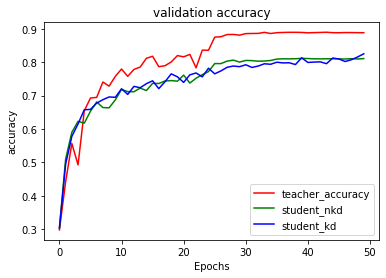

In [11]:
student_nkd = history_student_nkd.history['val_accuracy']
student_kd = history_student_kd
teacher = history_teacher.history['val_accuracy']
plt.plot(range(0,epochs),teacher,'r',label='teacher_accuracy')
plt.plot(range(0,epochs), student_nkd, 'g', label='student_nkd')
plt.plot(range(0,epochs), student_kd, 'b', label='student_kd')
plt.title('validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()
plt.show()